In [285]:
import h5py # package was installed and found for hdf5 format

from matplotlib import pyplot as plt
import matplotlib.colors as colors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import warnings
from astropy import units as u, constants as const
from meshoid import Meshoid, load_from_snapshot
%matplotlib inline

from os.path import isfile
from urllib.request import urlretrieve
import shutil 



In [261]:
# the raytracer below cannot cache its compiled kernel, which is harmless here
warnings.filterwarnings("ignore", message=".*Cannot cache compiled function.*")

# coordinates for a square map, for pcolormesh
def grid(halfwidth, res):
    a = np.linspace(-halfwidth, halfwidth, res)
    return np.meshgrid(a, a, indexing="ij")

def chck_snap(SNAPFILE):
    F = h5py.File(SNAPFILE,'r')
    print(list(F.keys()))   # if we don't see PartType5, then we don't have sinks
    F.close()

# check dimension of metalicity of gas to see if jet fraction is in there
def chck_z(SNAPFILE):
    with h5py.File(SNAPFILE,"r") as F:
        z_gas = F["PartType0/Metallicity"][:]
        print(z_gas.shape)  # yay if 14! 

def chck_units(SNAPFILE):
    # get some units!
    with h5py.File(SNAPFILE,"r") as F:
        header = F["Header"]
        unit_length = F["Header"].attrs["UnitLength_In_CGS"]*u.cm   # is 1pc
        unit_mass = F["Header"].attrs["UnitMass_In_CGS"] * u.g   # is 1msol
        unit_velocity = F["Header"].attrs["UnitVelocity_In_CGS"] * u.cm / u.s   # is 100 cm/s  = 1 m/s
        unit_density = unit_mass / unit_length**3
        print(unit_length)
        print(unit_mass)
        print(unit_velocity)

        code_time_to_Myr = (u.pc/(u.m/u.s)).to('Myr')
        time_Myr = F["Header"].attrs['Time'] *code_time_to_Myr
        print('snap time {:.3f} Myr'.format(time_Myr)) # timestamp of this snapshot

def read_in_stuff(SNAPFILE):
    with h5py.File(SNAPFILE,"r") as F:
        z_gas = F["PartType0/Metallicity"][:]  # get jet fractions 
        print('z_gas shape',z_gas.shape)  # yay 14 big
        f_jet = z_gas[:,11]  # jet fraction 
        #f_jet = 0 
        x_gas = F["PartType0/Coordinates"][:]  # get gas coordinates
        v_gas = F["PartType0/Velocities"][:]  # get gas velocities
        v2_gas = np.sum(v_gas*v_gas, axis=1)
        va_gas = np.sqrt(v2_gas)  # |v| for gas 

        x_part = F["PartType5/Coordinates"][:]   # get sink particle coordinates
        print('x_part shape',x_part.shape)  # we only have a thousand or so sinks
        v_part = F["PartType5/Velocities"][:]  # get particle velocities
        md_part = F["PartType5/BH_Mdot"][:]   # accretion rate?
        j_part =  F["PartType5/BH_Specific_AngMom"][:]   # angular momentum vector 
        
    return x_gas,v_gas,z_gas,f_jet,va_gas,x_part,v_part,md_part,j_part

url_base =  "https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/"

In [286]:
run= "STARFORGE_v1.3/M2e3_R3/M2e3_R3_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output/"
print(url_base + run)
data_dir = 'M2e3_R3/'

SNAPFILE = 'snapshot_1000.hdf5' 
URL = url_base + run + SNAPFILE
urlretrieve(URL, SNAPFILE)  # is 350MBytes
shutil.move(SNAPFILE, data_dir+SNAPFILE)

https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.3/M2e3_R3/M2e3_R3_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output/


'M2e3_R3/snapshot_1000.hdf5'

In [247]:
# /mnt/ceph/users/starforge/STARFORGE_RT/STARFORGE_v1.3/M2e4_R10/M2e4_R10_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output
run = "STARFORGE_v1.3/M2e4_R10/M2e4_R10_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output/"
print(url_base + run)
# these are only 350 MByte! res is low and we could try things quickly 
#SNAPFILE = 'snapshot_6240.hdf5'  
SNAPFILE = 'snapshot_2100.hdf5' 
URL = url_base + run + SNAPFILE
urlretrieve(URL, SNAPFILE)  # is 350MBytes

# I downloaded 1400 - 3300 and put in subdirectory

https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.3/M2e4_R10/M2e4_R10_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output/


('snapshot_2100.hdf5', <http.client.HTTPMessage at 0x138976df0>)

In [274]:
# downloaded every 100 , though there is a file for every 10 
# there is a problem with 3000 file
# I moved data into the directory M2e4_R10
data_dir = 'M2e4_R10/'

ndigits = 4  # numbers of digits in filename
def mkfilename(data_dir,index):
    ifile = ""
    for k in range(ndigits):
        if (index < 10**k):
            ifile = ifile + '0'
    ifile += '{:d}'.format(index)
    snapfile = data_dir + 'snapshot_' + ifile + '.hdf5'
    print(snapfile)
    return snapfile



M2e4_R10/snapshot_0111.hdf5


'M2e4_R10/snapshot_0111.hdf5'

In [282]:
for k in range(1400,3400,100):
    snapfile = mkfilename(data_dir,k)
    chck_snap(snapfile)
    #chck_units(snapfile) 

M2e4_R10/snapshot_1400.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_1500.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_1600.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_1700.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_1800.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_1900.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2000.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2100.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2200.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2300.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2400.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2500.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2600.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2700.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2800.hdf5
['Header', 'PartType0', 'PartType5']
M2e4_R10/snapshot_2900.hd

In [283]:
for k in range(1400,3400,100):
    snapfile = mkfilename(data_dir,k)
    chck_z(snapfile)

M2e4_R10/snapshot_1400.hdf5
(2473176, 14)
M2e4_R10/snapshot_1500.hdf5
(2471810, 14)
M2e4_R10/snapshot_1600.hdf5
(2470275, 14)
M2e4_R10/snapshot_1700.hdf5
(2468258, 14)
M2e4_R10/snapshot_1800.hdf5
(2466450, 14)
M2e4_R10/snapshot_1900.hdf5
(2465035, 14)
M2e4_R10/snapshot_2000.hdf5
(2462645, 14)
M2e4_R10/snapshot_2100.hdf5
(2457072, 14)
M2e4_R10/snapshot_2200.hdf5
(2447573, 14)
M2e4_R10/snapshot_2300.hdf5
(2442108, 14)
M2e4_R10/snapshot_2400.hdf5
(2437267, 14)
M2e4_R10/snapshot_2500.hdf5
(2429279, 14)
M2e4_R10/snapshot_2600.hdf5
(2420120, 14)
M2e4_R10/snapshot_2700.hdf5
(2402662, 14)
M2e4_R10/snapshot_2800.hdf5
(2392503, 14)
M2e4_R10/snapshot_2900.hdf5
(2385250, 14)
M2e4_R10/snapshot_3000.hdf5


OSError: Can't synchronously read data (filter returned failure during read)

In [262]:
SNAPFILE = 'snapshot_2200.hdf5' 
chck_snap(SNAPFILE)
chck_z(SNAPFILE)
chck_units(SNAPFILE)
# seems good
SNAPFILE = 'snapshot_3000.hdf5' 
chck_snap(SNAPFILE)
chck_z(SNAPFILE)
chck_units(SNAPFILE)  # outputs every 25 kyr

['Header', 'PartType0', 'PartType5']
(2447573, 14)
3.09e+18 cm
1.99e+33 g
100.0 cm / s
snap time 5.421 Myr
['Header', 'PartType0', 'PartType5']


OSError: Can't synchronously read data (filter returned failure during read)

In [225]:
(5.446-5.421)*1e3

24.999999999999467

z_gas shape (2442108, 14)
x_part shape (106, 3)


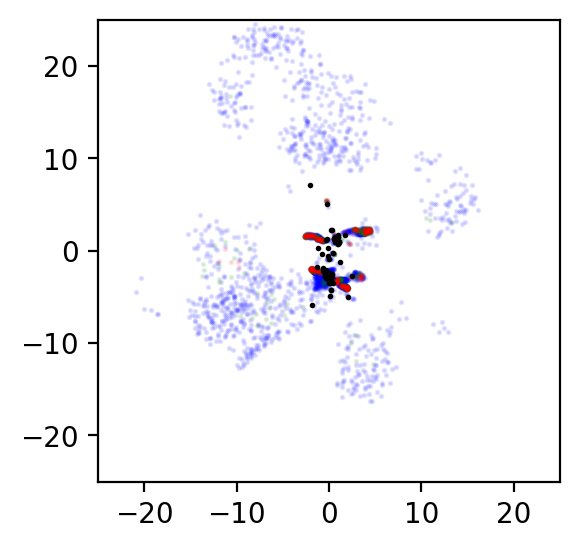

In [255]:


def plt1(SNAPFILE):
    x_gas,v_gas,z_gas,f_jet,va_gas,x_part,v_part,md_part,j_part=read_in_stuff(SNAPFILE)
    c0x = 50
    c0y=  50
    
    fig,ax = plt.subplots(1,1,figsize=(3,3),dpi=200)

    junk = np.logical_and(va_gas>10000,va_gas<20000)
    x_jet = x_gas[junk,0] - c0x
    y_jet = x_gas[junk,1] - c0y
    ax.scatter(x_jet,y_jet,s=1,color='blue',alpha=0.1)
    
    junk = np.logical_and(va_gas>20000,va_gas<30000)
    x_jet = x_gas[junk,0] - c0x
    y_jet = x_gas[junk,1] - c0y
    ax.scatter(x_jet,y_jet,s=1,color='green',alpha=0.1)

    junk = np.logical_and(va_gas>30000,va_gas<40000)
    x_jet = x_gas[junk,0] - c0x
    y_jet = x_gas[junk,1] - c0y
    ax.scatter(x_jet,y_jet,s=1,color='red',alpha=0.1)
    
    
    ax.scatter(x_part[:,0]-c0x,x_part[:,1]-c0y,s=1,color='black')
    xmax = 25
    ax.set_xlim([-xmax,xmax])
    ax.set_ylim([-xmax,xmax])
    ax.set_aspect(1)
    plt.show()


SNAPFILE = 'snapshot_2300.hdf5' 
plt1(SNAPFILE)

z_gas shape (2462645, 14)
x_part shape (70, 3)


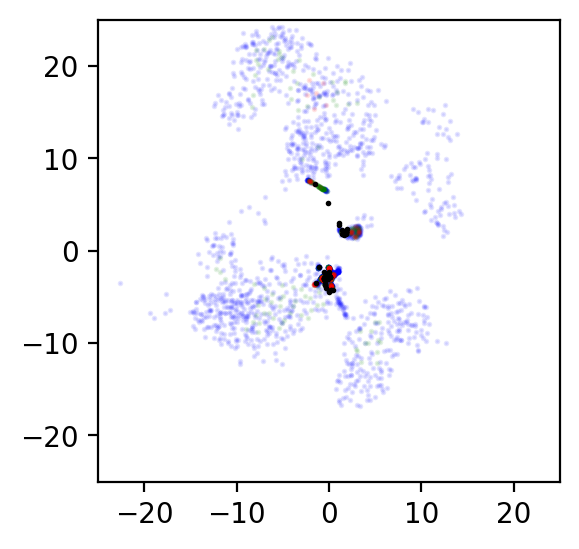

z_gas shape (2457072, 14)
x_part shape (84, 3)


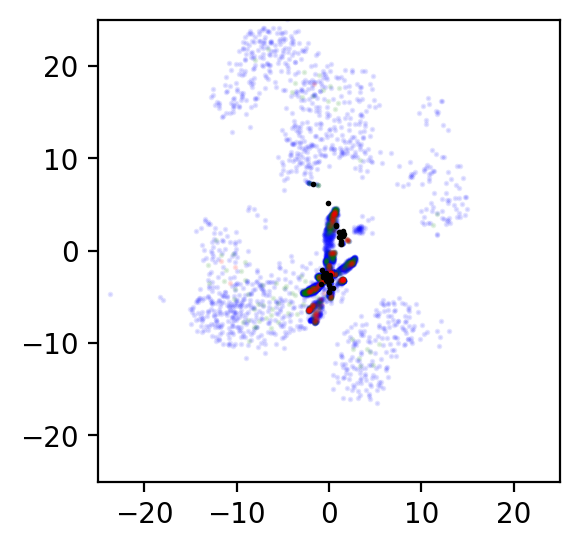

z_gas shape (2447573, 14)
x_part shape (101, 3)


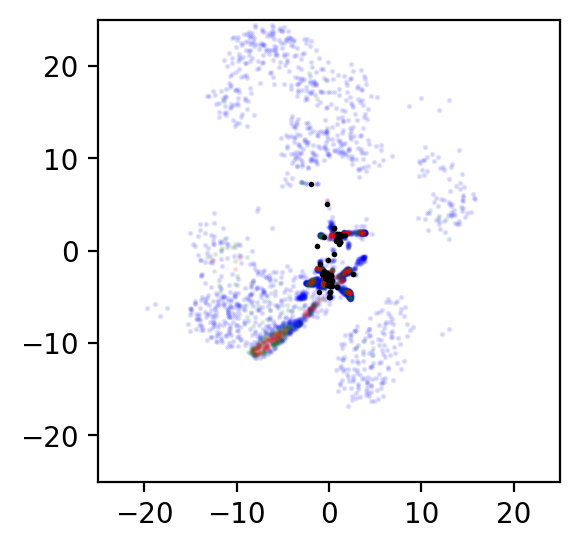

z_gas shape (2442108, 14)
x_part shape (106, 3)


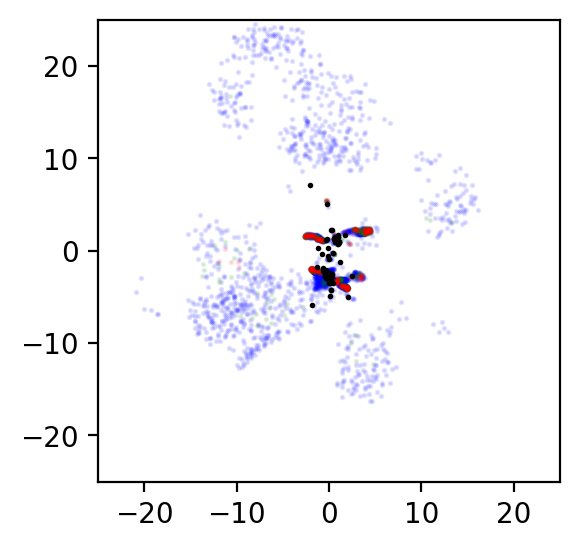

z_gas shape (2437267, 14)
x_part shape (131, 3)


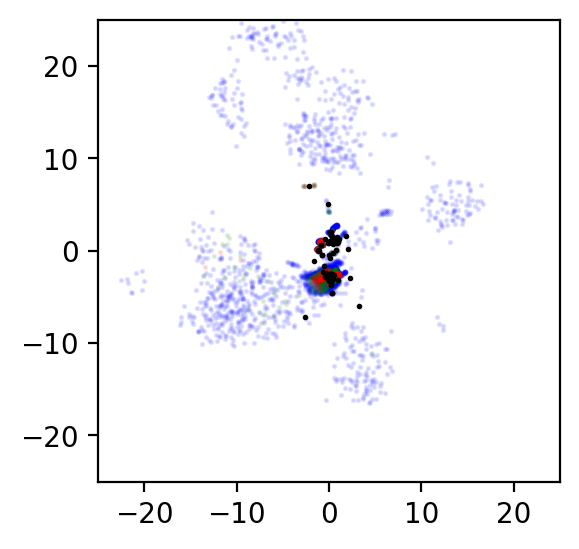

z_gas shape (2429279, 14)
x_part shape (158, 3)


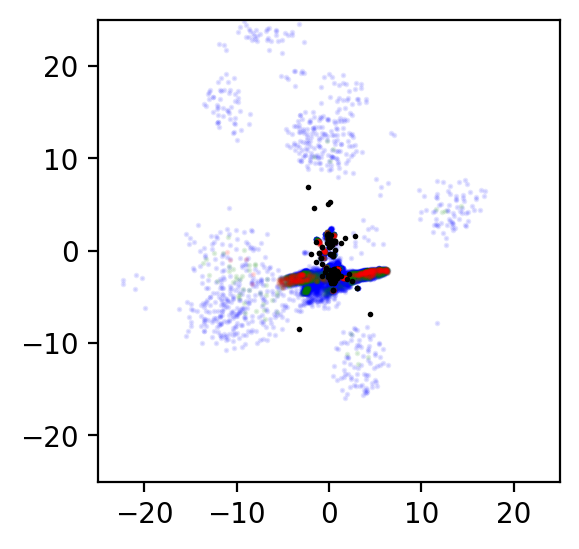

z_gas shape (2420120, 14)
x_part shape (176, 3)


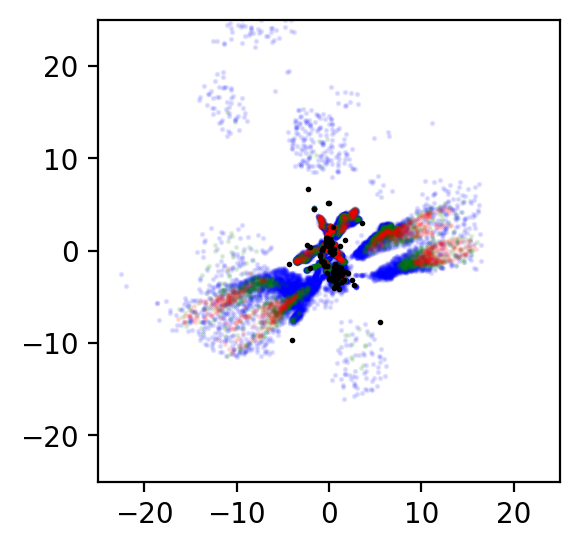

z_gas shape (2402662, 14)
x_part shape (181, 3)


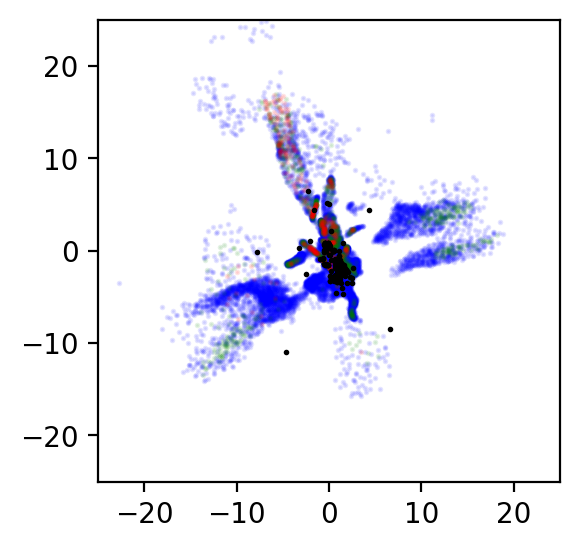

z_gas shape (2392503, 14)
x_part shape (194, 3)


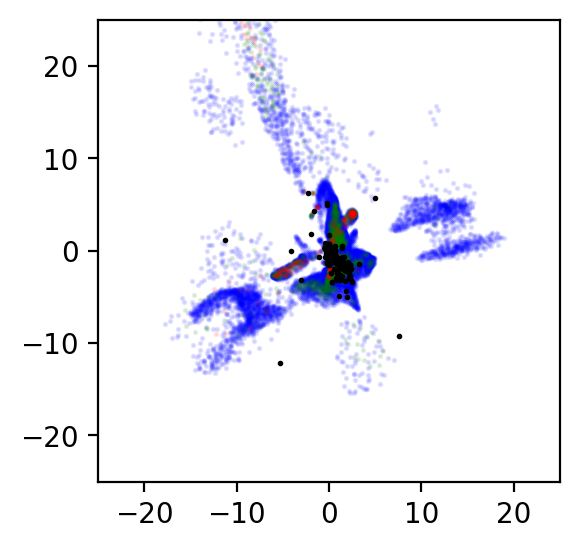

In [256]:
SNAPFILE = 'snapshot_2000.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_2100.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_2200.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_2300.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_2400.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_2500.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_2600.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_2700.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_2800.hdf5' 
plt1(SNAPFILE)

z_gas shape (2385250, 14)
x_part shape (210, 3)


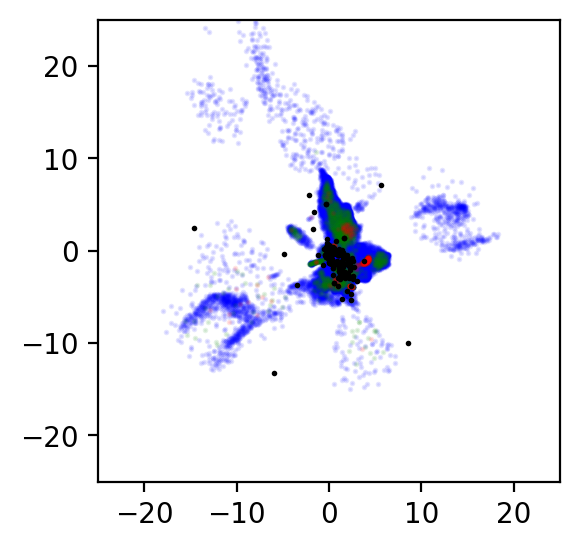

z_gas shape (2376849, 14)
x_part shape (237, 3)


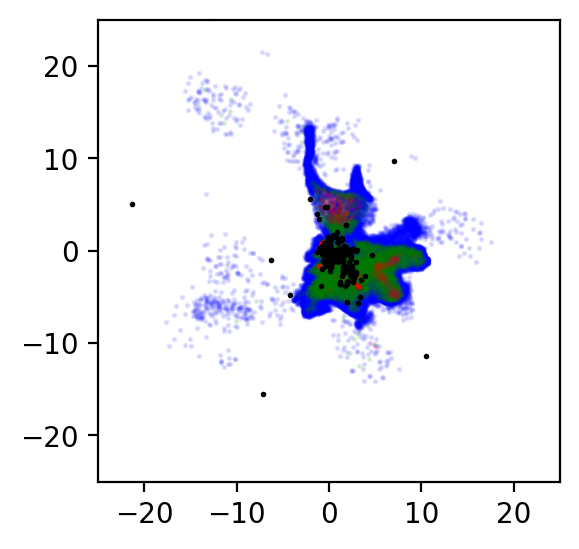

In [265]:
SNAPFILE = 'snapshot_2900.hdf5' 
plt1(SNAPFILE)

SNAPFILE = 'snapshot_3100.hdf5' 
plt1(SNAPFILE)

In [211]:
md_part

array([0.0000000e+00, 0.0000000e+00, 8.6780371e+03, 1.0504258e-01,
       6.3921208e-33, 2.9317478e+03, 9.7724375e+03, 8.6684961e+03,
       1.3269821e-28, 9.0544912e+03, 3.4163341e-01, 2.7971215e-15,
       2.9031849e-25, 5.9329888e+03, 1.4291482e+03, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 4.1569911e-06, 6.2652836e-03,
       7.1457865e-16, 0.0000000e+00, 0.0000000e+00, 7.0471112e+02,
       0.0000000e+00, 1.9646133e-21, 0.0000000e+00, 2.9685037e+03,
       5.7495053e-09, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 3.0482568e-11,
       4.4508810e-11, 4.5821081e-32, 6.8428818e+03, 1.5448044e-12,
       6.5721459e-22, 2.5272374e-31, 8.1696906e+02, 1.9514201e-13,
       0.0000000e+00, 1.0102368e-27, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 1.0189470e-11, 6.5185862e-17,
       6.4912246e+03, 2.3137633e+04, 2.3813306e-01, 2.7330629e

In [152]:
va_gas

array([10942.113, 10241.59 , 10850.462, ..., 26935.096, 31176.43 ,
       35361.344], dtype=float32)

In [182]:
v_gas[1,:]

array([-9923.187 ,  2393.547 ,  -831.5363], dtype=float32)

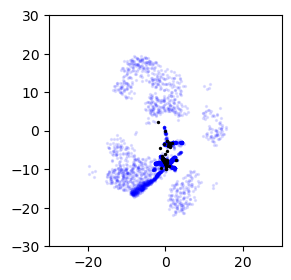

In [228]:
c0x = 50
c0y=  55
junk = va_gas>10000
x_jet = x_gas[junk,0] - c0x
y_jet = x_gas[junk,1] - c0y

fig,ax = plt.subplots(1,1,figsize=(3,3))

ax.scatter(x_jet,y_jet,s=2,color='blue',alpha=0.1)
ax.scatter(x_part[:,0]-c0x,x_part[:,1]-c0y,s=2,color='black')
xmax = 30
ax.set_xlim([-xmax,xmax])
ax.set_ylim([-xmax,xmax])
plt.show()
# alot of gas has been evacuated from the cloud at this time step 

In [209]:
F = h5py.File(SNAPFILE,'r')

In [180]:
print(np.mean(v_gas[:,0]))
print(np.mean(v_gas[:,1]))
print(np.mean(v_gas[:,2]))
print(np.mean(va_gas))

-141.886
100.085594
-82.947685
12178.813


In [51]:
url_base =  "https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/"
run = "STARFORGE_v1.2/M2e4_R1/M2e4_R1_Z1_S0_A2_B0.1_I10000_Res271_n2_sol0.5_42/output_turbsphere_driving1/"
print(url_base + run)
SNAPFILE = 'snapshot_3000.hdf5'  
URL = url_base + run + SNAPFILE

urlretrieve(URL, SNAPFILE)  # is 3GBytes

https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.2/M2e4_R1/M2e4_R1_Z1_S0_A2_B0.1_I10000_Res271_n2_sol0.5_42/output_turbsphere_driving1/


('snapshot_3000.hdf5', <http.client.HTTPMessage at 0x12e2f8130>)

In [52]:
F = h5py.File(SNAPFILE,'r')
list(F.keys()) 

['Header', 'PartType0', 'PartType5']

In [ ]:
# yay! we have PartType5 on this one!

In [53]:
list(F['PartType0'].keys())

['Coordinates',
 'Density',
 'DustToGasRatio_Local',
 'Dust_Temperature',
 'ElectronAbundance',
 'HII',
 'IRBand_Radiation_Temperature',
 'InternalEnergy',
 'MagneticField',
 'Masses',
 'Metallicity',
 'MolecularMassFraction',
 'NeutralHydrogenAbundance',
 'ParticleChildIDsNumber',
 'ParticleIDGenerationNumber',
 'ParticleIDs',
 'PhotonEnergy',
 'PhotonFluxDensity',
 'Potential',
 'Pressure',
 'SmoothingLength',
 'SoundSpeed',
 'Temperature',
 'TurbulenceDriving',
 'Velocities']

In [54]:
list(F['PartType5'].keys())

['BH_AccretionLength',
 'BH_Mass',
 'BH_Mass_AlphaDisk',
 'BH_Mdot',
 'BH_NProgs',
 'BH_Specific_AngMom',
 'Coordinates',
 'DustToGasRatio_Local',
 'Mass_D',
 'Masses',
 'Metallicity',
 'ParticleChildIDsNumber',
 'ParticleIDGenerationNumber',
 'ParticleIDs',
 'Potential',
 'ProtoStellarAge',
 'ProtoStellarRadius_inSolar',
 'ProtoStellarStage',
 'SinkInitialMass',
 'SinkRadius',
 'StarLuminosity_Solar',
 'StellarFormationTime',
 'Velocities',
 'ZAMS_Mass']

In [55]:
list(s_F["Header"].attrs.keys())

['BAL_f_accretion',
 'BAL_f_launch_v',
 'BAL_internal_temperature',
 'BAL_v_outflow',
 'BlackHoleAccretionFactor',
 'BlackHoleEddingtonFactor',
 'BlackHoleFeedbackFactor',
 'BlackHoleMaxAccretionRadius',
 'BlackHoleNgbFactor',
 'BlackHoleRadiativeEfficiency',
 'BoxSize',
 'Cell_Spawn_Mass_ratio',
 'Cell_Spawn_Mass_ratio_MS',
 'ComovingIntegrationOn',
 'Density_Threshold_For_SF_CodeUnits',
 'Effective_Kernel_NeighborNumber',
 'Fixed_ForceSoftening_Keplerian_Kernel_Extent',
 'Flag_Cooling',
 'Flag_DoublePrecision',
 'Flag_Feedback',
 'Flag_IC_Info',
 'Flag_Metals',
 'Flag_Sfr',
 'Flag_StellarAge',
 'GIZMO_version',
 'Gravitational_Constant_In_Code_Inits',
 'HubbleParam',
 'Internal_UnitB_In_Gauss',
 'InterstellarRadiationFieldStrength',
 'Kernel_Function_ID',
 'MassTable',
 'Maximum_Mass_For_Cell_Split',
 'Metals_Atomic_Number_Or_Key',
 'Minimum_Mass_For_Cell_Merge',
 'NumFilesPerSnapshot',
 'NumPart_ThisFile',
 'NumPart_Total',
 'NumPart_Total_HighWord',
 'Radiation_RHD_Max_Bin_Freq_in_

In [90]:
# get some units!
header = F["Header"]
unit_length = F["Header"].attrs["UnitLength_In_CGS"]*u.cm   # is 1pc
unit_mass = F["Header"].attrs["UnitMass_In_CGS"] * u.g   # is 1msol
unit_velocity = F["Header"].attrs["UnitVelocity_In_CGS"] * u.cm / u.s   # is 100 cm/s  = 1 m/s
unit_density = unit_mass / unit_length**3

In [96]:
print(unit_velocity)
print(unit_density)

100.0 cm / s
6.769911178294541e-23 g / cm3


In [58]:
z_gas = F["PartType0/Metallicity"][:]  # get jet fractions 
print(z_gas.shape)  # yay 14 big
f_jet = z_gas[:,11]  # jet fraction 
x_part = F["PartType5/Coordinates"][:]   # get sink particle coordinates
print(x_part.shape)  # we only have a thousand or so sinks
x_gas = F["PartType0/Coordinates"][:]  # get gas coordinates


(19539381, 14)


In [76]:
v_gas = F["PartType0/Velocities"][:]  # get gas velocities
v_part = F["PartType5/Velocities"][:]  # get particle velocities

In [111]:
T_gas = F["PartType0/Temperature"][:]  # get gas temperature

In [113]:
T_gas  # not sure what the units are for this, but it seems to range to very high values 

array([ 31.486605,  87.67197 , 104.36634 , ...,  76.03487 ,  76.96986 ,
        65.15888 ], dtype=float32)

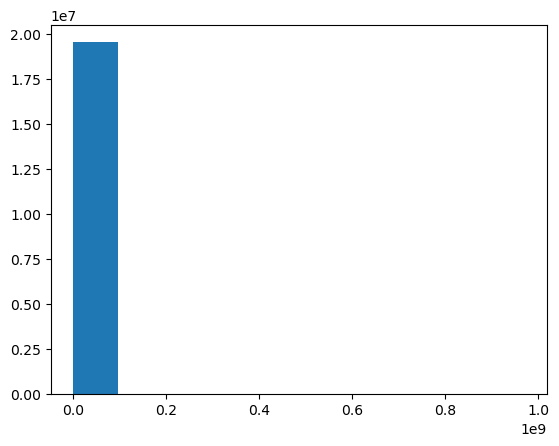

In [112]:
plt.hist(T_gas)
plt.show()

In [108]:
np.sum(f_jet > 0.2)  # there are plenty of jet particles 

np.int64(210391)

In [119]:
np.sum(T_gas>1e5)  #many high temperature particles 

np.int64(13129)

In [64]:
x_jet = x_gas[f_jet>0.5,0] - 5
y_jet = x_gas[f_jet>0.5,1] - 5
fig,ax = plt.subplots(1,1,figsize=(3,3))
ax.plot(x_part[:,0]-5,x_part[:,1]-5,'k.')
ax.plot(x_jet,y_jet, 'b.')
ax.set_xlim([-2,2])
ax.set_ylim([-2,2])
plt.show()

In [128]:
junk = np.logical_and(f_jet>0.5,f_jet<0.7) 
junk = np.logical_and(f_jet>0.5, np.abs(

array([False, False, False, ..., False, False, False])

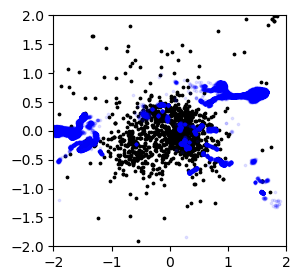

In [130]:
c0=5; 
junk = T_gas>1e5  # does not pull out jets 
junk = f_jet>0.5

x_jet = x_gas[junk,0] - c0
y_jet = x_gas[junk,1] - c0
fig,ax = plt.subplots(1,1,figsize=(3,3))
ax.scatter(x_part[:,0]-c0,x_part[:,1]-c0,s=3,color='black')
ax.scatter(x_jet,y_jet,s=3,color='blue',alpha=0.1)
ax.set_xlim([-2,2])
ax.set_ylim([-2,2])
plt.show()

(19539381, 14)


In [39]:
url_base = "https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/"
run = "STARFORGE_v1.2/M2e4_R1/M2e4_R1_Z1_S0_A2_B0.1_I10000_Res271_n2_sol0.5_42/output_turbsphere_stirring/"
print(url_base + run)
SNAPFILE = 'snapshot_050.hdf5'  
URL = url_base + run + SNAPFILE

urlretrieve(URL, SNAPFILE)  # is 3GBytes

#Looks like 50 snaps, has a stars subdirectory?

# we chose and downloaded a snap successfully this way 


https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.2/M2e4_R1/M2e4_R1_Z1_S0_A2_B0.1_I10000_Res271_n2_sol0.5_42/output_turbsphere_stirring/


('snapshot_050.hdf5', <http.client.HTTPMessage at 0x12f8aa950>)

In [42]:
s_run = run + 'stars/'
s_SNAPFILE = 'snapshot_050_stars.hdf5'  
s_URL = url_base + s_run + s_SNAPFILE
urlretrieve(s_URL, s_SNAPFILE)  # is  3GBytes

('snapshot_050_stars.hdf5', <http.client.HTTPMessage at 0x12fd456d0>)

In [46]:
F = h5py.File(SNAPFILE,'r')
list(F.keys()) 

['Header', 'PartType0']

In [48]:
list(F['PartType0'].keys())

['Coordinates',
 'Density',
 'DustToGasRatio_Local',
 'Dust_Temperature',
 'ElectronAbundance',
 'HII',
 'IRBand_Radiation_Temperature',
 'InternalEnergy',
 'MagneticField',
 'Masses',
 'Metallicity',
 'MolecularMassFraction',
 'NeutralHydrogenAbundance',
 'ParticleChildIDsNumber',
 'ParticleIDGenerationNumber',
 'ParticleIDs',
 'PhotonEnergy',
 'PhotonFluxDensity',
 'Potential',
 'Pressure',
 'SmoothingLength',
 'SoundSpeed',
 'StarFormationRate',
 'Temperature',
 'TurbulenceDissipation',
 'TurbulenceDriving',
 'Velocities',
 'VelocityDivergence',
 'Vorticity']

In [49]:
list(F['Header'].keys())

[]

In [43]:
s_F =  h5py.File(s_SNAPFILE,'r')
list(s_F.keys()) 

['Header']

In [44]:
list(s_F["Header"].attrs.keys())

['BAL_f_accretion',
 'BAL_f_launch_v',
 'BAL_internal_temperature',
 'BAL_v_outflow',
 'BlackHoleAccretionFactor',
 'BlackHoleEddingtonFactor',
 'BlackHoleFeedbackFactor',
 'BlackHoleMaxAccretionRadius',
 'BlackHoleNgbFactor',
 'BlackHoleRadiativeEfficiency',
 'BoxSize',
 'Cell_Spawn_Mass_ratio',
 'Cell_Spawn_Mass_ratio_MS',
 'ComovingIntegrationOn',
 'Density_Threshold_For_SF_CodeUnits',
 'Effective_Kernel_NeighborNumber',
 'Fixed_ForceSoftening_Keplerian_Kernel_Extent',
 'Flag_Cooling',
 'Flag_DoublePrecision',
 'Flag_Feedback',
 'Flag_IC_Info',
 'Flag_Metals',
 'Flag_Sfr',
 'Flag_StellarAge',
 'GIZMO_version',
 'Gravitational_Constant_In_Code_Inits',
 'HubbleParam',
 'Internal_UnitB_In_Gauss',
 'InterstellarRadiationFieldStrength',
 'Kernel_Function_ID',
 'MassTable',
 'Maximum_Mass_For_Cell_Split',
 'Metals_Atomic_Number_Or_Key',
 'Minimum_Mass_For_Cell_Merge',
 'NumFilesPerSnapshot',
 'NumPart_ThisFile',
 'NumPart_Total',
 'NumPart_Total_HighWord',
 'Radiation_RHD_Max_Bin_Freq_in_

In [40]:
with h5py.File(SNAPFILE,"r") as F:
    z_gas = F["PartType0/Metallicity"][:]
print(z_gas.shape)  # yay 14 big, 

(24734537, 14)


In [ ]:
 #/mnt/ceph/users/starforge/STARFORGE_RT/STARFORGE_v1.2/M2e4_R1/M2e4_R1_Z1_S0_A2_B0.1_I10000_Res271_n2_sol0.5_42/output_turbsphere_stirring

In [ ]:
sfile = chttps://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.3/M2e4_R3/M2e4_R3_Z1_S0_A2_B0.1_I1_Res271_n2_sol0.5_42/output_turbsphere_stirring/"
URL = sfile + 'snapshot_030.hdf5'
SNAPFILE = 'snapshot_030.hdf5'
urlretrieve(URL, SNAPFILE)

# we chose and downloaded a snap successfully this way 

# this data set is no good because no sink particles our outflows!

In [13]:
SNAPNUM = 30
header = lambda key: load_from_snapshot(key, 0, ".", SNAPNUM)  # a function that returns a header keyword value
unit_length = header("UnitLength_In_CGS") * u.cm
print(unit_length)

3.09e+18 cm


In [14]:
unit_length = header("UnitLength_In_CGS") * u.cm
unit_mass = header("UnitMass_In_CGS") * u.g
unit_velocity = header("UnitVelocity_In_CGS") * u.cm / u.s
unit_density = unit_mass / unit_length**3
assert header("ComovingIntegrationOn") == 0 and header("HubbleParam") == 1  # no h or a factors

pos = load_from_snapshot("Coordinates", 0, ".", SNAPNUM) * unit_length
mass = load_from_snapshot("Masses", 0, ".", SNAPNUM) * unit_mass
hsml = load_from_snapshot("SmoothingLength", 0, ".", SNAPNUM) * unit_length
rho = load_from_snapshot("Density", 0, ".", SNAPNUM) * unit_density

# hydrogen mass fraction from the abundances this run adopted (index 0 is total
# metallicity, 1 is helium); per-cell values are in the Metallicity dataset
X_H = 1 - header("Solar_Abundances_Adopted")[:2].sum()
n_H = (rho * X_H / const.m_p).to(u.cm**-3)

boxsize = header("BoxSize") * unit_length

In [25]:
F = h5py.File(SNAPFILE,'r')
list(F["Header"].attrs.keys())

['BlackHoleAccretionFactor',
 'BlackHoleEddingtonFactor',
 'BlackHoleFeedbackFactor',
 'BlackHoleMaxAccretionRadius',
 'BlackHoleNgbFactor',
 'BlackHoleRadiativeEfficiency',
 'BoxSize',
 'ComovingIntegrationOn',
 'Density_Threshold_For_SF_CodeUnits',
 'Effective_Kernel_NeighborNumber',
 'Fixed_ForceSoftening_Keplerian_Kernel_Extent',
 'Flag_Cooling',
 'Flag_DoublePrecision',
 'Flag_Feedback',
 'Flag_IC_Info',
 'Flag_Metals',
 'Flag_Sfr',
 'Flag_StellarAge',
 'GIZMO_version',
 'Gravitational_Constant_In_Code_Inits',
 'HubbleParam',
 'Internal_UnitB_In_Gauss',
 'InterstellarRadiationFieldStrength',
 'Kernel_Function_ID',
 'MassTable',
 'Maximum_Mass_For_Cell_Split',
 'Metals_Atomic_Number_Or_Key',
 'Minimum_Mass_For_Cell_Merge',
 'NumFilesPerSnapshot',
 'NumPart_ThisFile',
 'NumPart_Total',
 'NumPart_Total_HighWord',
 'Radiation_RHD_Max_Bin_Freq_in_eV',
 'Radiation_RHD_Min_Bin_Freq_in_eV',
 'Redshift',
 'SNe_Energy_Normalization_FromSSP',
 'SeedAlphaDiskMass',
 'SeedBlackHoleMass',
 'Sol

In [ ]:
# this is nice but is missing the PartType information!

In [35]:
list(F.keys())  # this data set does not contain the sink particles! 

['Header', 'PartType0']

In [26]:
list(F["PartType0"].attrs.keys())

[]

In [29]:
F["PartType0"]

<HDF5 group "/PartType0" (25 members)>

In [31]:
for k in F["PartType0"]:
    print (k)
# this is cool!

Coordinates
Density
DustToGasRatio_Local
Dust_Temperature
ElectronAbundance
HII
IRBand_Radiation_Temperature
InternalEnergy
MagneticField
Masses
Metallicity
MolecularMassFraction
NeutralHydrogenAbundance
ParticleChildIDsNumber
ParticleIDGenerationNumber
ParticleIDs
PhotonEnergy
PhotonFluxDensity
Potential
Pressure
SmoothingLength
SoundSpeed
Temperature
TurbulenceDriving
Velocities


In [34]:
F["PartType5"]

KeyError: "Unable to synchronously open object (object 'PartType1' doesn't exist)"

In [32]:
for k in F["PartType5"]:
    print (k)

KeyError: "Unable to synchronously open object (object 'PartType5' doesn't exist)"

In [20]:
code_time_to_Myr = (u.pc/(u.m/u.s)).to('Myr')
time_Myr = F["Header"].attrs['Time'] *code_time_to_Myr
print(time_Myr)  # timestamp of this snapshot

1.209827456534544


In [22]:
# gas coordinates
with h5py.File(SNAPFILE,"r") as F:
    x_gas = F["PartType0/Coordinates"][:]
print(x_gas.shape)

(24734675, 3)


In [23]:
# gas metalliticities
with h5py.File(SNAPFILE,"r") as F:
    z_gas = F["PartType0/Metallicity"][:]
print(z_gas.shape)
# the trailing 3 fields that are supposed to hold jet wind fractions are not there. 
# the size of the array should be 14

(24734675, 11)


In [24]:
gasdata = {k: F["PartType0"][k][:] for k in F["PartType0"]}

KeyError: 'Unable to synchronously open object (invalid identifier type to function)'

In [1]:

SNAPNUM = 2590
SNAPFILE = f"snapshot_{SNAPNUM}.hdf5"
RUN = "M2e4_R10_Z1_S0_A2_B0.1_I1_Res271_n2_sol0.5_42"
URL = (
    "https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/"
    f"STARFORGE_v1.2/M2e4_R10/{RUN}/output/{SNAPFILE}"
)

if not isfile(SNAPFILE):  # feel free to use your own snapshots instead!
    print(f"downloading {SNAPFILE} (3.1 GB), this will take a while...")
    urlretrieve(URL, SNAPFILE)


downloading snapshot_2590.hdf5 (3.1 GB), this will take a while...


In [ ]:
#f = h5py.File('mytestfile.hdf5', 'r')

In [4]:
header = lambda key: load_from_snapshot(key, 0, ".", SNAPNUM)

unit_length = header("UnitLength_In_CGS") * u.cm
unit_mass = header("UnitMass_In_CGS") * u.g
unit_velocity = header("UnitVelocity_In_CGS") * u.cm / u.s
unit_density = unit_mass / unit_length**3
assert header("ComovingIntegrationOn") == 0 and header("HubbleParam") == 1  # no h or a factors

pos = load_from_snapshot("Coordinates", 0, ".", SNAPNUM) * unit_length
mass = load_from_snapshot("Masses", 0, ".", SNAPNUM) * unit_mass
hsml = load_from_snapshot("SmoothingLength", 0, ".", SNAPNUM) * unit_length
rho = load_from_snapshot("Density", 0, ".", SNAPNUM) * unit_density

# hydrogen mass fraction from the abundances this run adopted (index 0 is total
# metallicity, 1 is helium); per-cell values are in the Metallicity dataset
X_H = 1 - header("Solar_Abundances_Adopted")[:2].sum()
n_H = (rho * X_H / const.m_p).to(u.cm**-3)

boxsize = header("BoxSize") * unit_length
center = np.repeat(0.5, 3) * boxsize
print(f"{len(mass):,} gas cells totalling {mass.sum().to(u.Msun):.0f} in a {boxsize.to(u.pc):.0f} box")



23,682,804 gas cells totalling 23941 solMass in a 100 pc box


<Quantity 3.09e+18 cm>

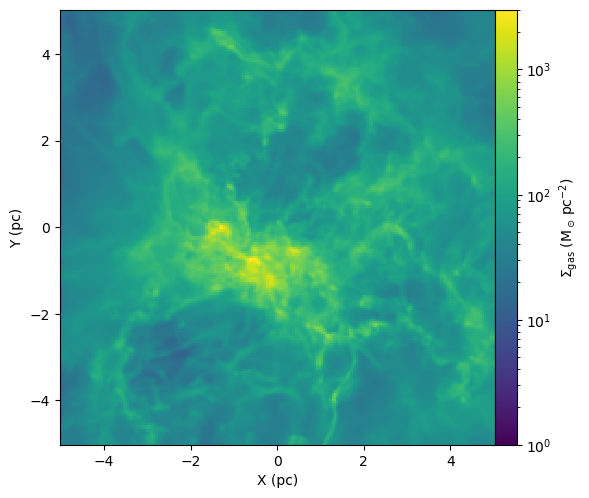

In [8]:
M = Meshoid(pos.to_value(u.pc), mass.to_value(u.Msun), hsml.to_value(u.pc))

RMAX = 5.0
RES = 200
X, Y = grid(RMAX, RES)

sigma_gas = (
    M.SurfaceDensity(M.m, center=center.to_value(u.pc), size=2 * RMAX, res=RES) * u.Msun / u.pc**2
)

fig, ax = plt.subplots(figsize=(6, 6))
p = ax.pcolormesh(X, Y, sigma_gas.value, norm=colors.LogNorm(vmin=1, vmax=3e3))
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.0)
fig.colorbar(p, label=r"$\Sigma_{\rm gas}$ $(\rm M_\odot\,pc^{-2})$", pad=0, cax=cax)
ax.set_aspect("equal")
ax.set_xlabel("X (pc)")
ax.set_ylabel("Y (pc)")
plt.tight_layout(h_pad=1)
plt.show()

#This does not work with the current snap that I downloaded that was kind of big. 

https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.3/M2e4_R3/M2e4_R3_Z1_S0_A2_B0.1_I1_Res271_n2_sol0.5_42/
mass 2e4 msol R3 = 3pc? Z1 = solar seems not on the list of 2021 as simulation was probably done in 2025
we can choose a turb mixing version here 
https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.3/M2e4_R3/M2e4_R3_Z1_S0_A2_B0.1_I1_Res271_n2_sol0.5_42/output_turbsphere_stirring/
there are about 73 snaps of 3Gb each

('snapshot_030.hdf5', <http.client.HTTPMessage at 0x12e368dd0>)

In [10]:
SNAPNUM = 20
SNAPFILE = f"snapshot_{SNAPNUM}.hdf5"
RUN = "M2e4_R3_Z1_S0_A2_B0.1_I1_Res271_n2_sol0.5_42"
URL = (
    "https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/"
    f"STARFORGE_v1.3/M2e4_R3/{RUN}/output_turbsphere_stirring/{SNAPFILE}"
)

if not isfile(SNAPFILE):  # feel free to use your own snapshots instead!
    print(f"downloading {SNAPFILE} (3.1 GB), this will take a while...")
    urlretrieve(URL, SNAPFILE)


downloading snapshot_20.hdf5 (3.1 GB), this will take a while...


HTTPError: HTTP Error 404: Not Found